In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from collections import Counter

from src.utils import (PROCESSED_DIR, METRIC_DIR, TABLE_DIR, FIG_DIR, MODEL_DIR,
                       save_fig, save_table, log_experiment, RANDOM_STATE)
from src.preprocessing import signed_log1p

sns.set_theme(style="whitegrid")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

with open(METRIC_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)
with open(METRIC_DIR / "feature_sets.json") as f:
    feature_sets = json.load(f)
with open(METRIC_DIR / "06c_best_params.json") as f:
    print("Saved tuning result (for cross-check):\n", json.dumps(json.load(f), indent=1)[:1500])

class_names = [c for c, i in sorted(label_mapping.items(), key=lambda kv: kv[1])]
FEATURES = feature_sets["CORR_FILTERED"]
print("\nFinal clue set:", len(FEATURES), "features")

Mounted at /content/drive
Saved tuning result (for cross-check):
 {
 "XGBoost": {
  "subsample": 1.0,
  "n_estimators": 200,
  "min_child_weight": 5,
  "max_depth": 6,
  "learning_rate": 0.2,
  "colsample_bytree": 1.0
 },
 "Random Forest": {
  "n_estimators": 100,
  "min_samples_split": 5,
  "min_samples_leaf": 1,
  "max_features": "sqrt",
  "max_depth": 30
 }
}

Final clue set: 48 features


In [2]:
train = pd.read_parquet(PROCESSED_DIR / "train.parquet", columns=FEATURES + ["Label_Group"])
y_train_multi = train["Label_Group"].map(label_mapping).values
y_train_bin = (y_train_multi != 0).astype(int)          # 0 = BENIGN, 1 = ATTACK

X_train = signed_log1p(train[FEATURES].values.astype("float32")).astype("float32")
del train

print("Training rows:", X_train.shape)
print("Binary:", Counter(y_train_bin))
print("10-class:", {class_names[k]: v for k, v in sorted(Counter(y_train_multi).items())})

Training rows: (1998384, 48)
Binary: Counter({np.int64(0): 1657803, np.int64(1): 340581})
10-class: {'BENIGN': 1657803, 'Bot': 1558, 'DDoS': 102411, 'DoS': 154984, 'FTP-Patator': 4745, 'Heartbleed': 9, 'Infiltration': 29, 'PortScan': 72555, 'SSH-Patator': 2575, 'Web Attack': 1715}


In [3]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

BEST = dict(n_estimators=200, max_depth=6, learning_rate=0.2,
            min_child_weight=5, subsample=1.0, colsample_bytree=1.0)

def make_xgb():
    return XGBClassifier(**BEST, tree_method="hist", n_jobs=-1,
                         random_state=RANDOM_STATE, verbosity=0)

def wrap(model):
    """Full pipeline: raw table -> array -> signed log -> model (so the app needs no extra steps)."""
    return Pipeline([("to_array", FunctionTransformer(np.asarray)),
                     ("log", FunctionTransformer(signed_log1p)),
                     ("model", model)])

BIN_PATH = MODEL_DIR / "binary_model.pkl"
if BIN_PATH.exists():
    print("[skip] binary model already saved")
else:
    t0 = time.time()
    m = make_xgb()
    m.fit(X_train, y_train_bin)
    joblib.dump(wrap(m), BIN_PATH)
    print(f"Binary model trained in {(time.time()-t0)/60:.1f} min and saved: {BIN_PATH.name}")

Binary model trained in 1.7 min and saved: binary_model.pkl


In [4]:
from imblearn.over_sampling import SMOTE

def smote_strategy(y):
    return {c: 2000 for c, n in Counter(y).items() if n < 2000}

MULTI_PATH = MODEL_DIR / "multiclass_model.pkl"
if MULTI_PATH.exists():
    print("[skip] multiclass model already saved")
else:
    t0 = time.time()
    sm = SMOTE(sampling_strategy=smote_strategy, k_neighbors=5, random_state=RANDOM_STATE)
    X_res, y_res = sm.fit_resample(X_train, y_train_multi)
    print("After SMOTE:", {class_names[k]: v for k, v in sorted(Counter(y_res).items())})
    m = make_xgb()
    m.fit(X_res, y_res)
    joblib.dump(wrap(m), MULTI_PATH)
    del X_res, y_res
    print(f"10-class model trained in {(time.time()-t0)/60:.1f} min and saved: {MULTI_PATH.name}")

with open(MODEL_DIR / "label_mapping.json", "w") as f:
    json.dump(label_mapping, f, indent=1)
with open(MODEL_DIR / "model_features.json", "w") as f:
    json.dump(FEATURES, f, indent=1)

After SMOTE: {'BENIGN': 1657803, 'Bot': 2000, 'DDoS': 102411, 'DoS': 154984, 'FTP-Patator': 4745, 'Heartbleed': 2000, 'Infiltration': 2000, 'PortScan': 72555, 'SSH-Patator': 2575, 'Web Attack': 2000}
10-class model trained in 15.6 min and saved: multiclass_model.pkl


In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, precision_recall_fscore_support)

test = pd.read_parquet(PROCESSED_DIR / "test.parquet", columns=FEATURES + ["Label_Group"])
y_test_multi = test["Label_Group"].map(label_mapping).values
y_test_bin = (y_test_multi != 0).astype(int)
X_test = test[FEATURES]
print("Test rows:", len(test))
print("Test class counts:", {class_names[k]: v for k, v in sorted(Counter(y_test_multi).items())})

bin_model = joblib.load(BIN_PATH)
multi_model = joblib.load(MULTI_PATH)

# ---------- BINARY ----------
proba_b = bin_model.predict_proba(X_test)[:, 1]
pred_b = (proba_b >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test_bin, pred_b).ravel()
bin_metrics = {
    "accuracy": accuracy_score(y_test_bin, pred_b),
    "precision": precision_score(y_test_bin, pred_b),
    "recall": recall_score(y_test_bin, pred_b),
    "f1": f1_score(y_test_bin, pred_b),
    "roc_auc": roc_auc_score(y_test_bin, proba_b),
    "pr_auc": average_precision_score(y_test_bin, proba_b),
    "false_alarm_rate": fp / (fp + tn),
    "missed_attacks": int(fn),
    "false_alarms": int(fp),
}
bin_df = pd.DataFrame([bin_metrics]).round(5)
print("\n=== BINARY (BENIGN vs ATTACK) on the locked test set ===")
print(bin_df.T.to_string(header=False))
save_table(bin_df, "07_test_binary_metrics", index=False)
np.save(METRIC_DIR / "07_test_proba_binary.npy", proba_b)

# ---------- 10-CLASS ----------
pred_m = multi_model.predict(X_test)
labels = list(range(len(class_names)))
p, r, f, s = precision_recall_fscore_support(y_test_multi, pred_m, labels=labels, zero_division=0)
per_class = pd.DataFrame({"class": class_names, "precision": p, "recall": r, "f1": f, "test rows": s}).round(4)
multi_summary = {
    "accuracy": accuracy_score(y_test_multi, pred_m),
    "macro_f1": f1_score(y_test_multi, pred_m, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test_multi, pred_m, average="weighted", zero_division=0),
    "false_alarm_rate": 1 - r[0],
}
print("\n=== 10-CLASS on the locked test set ===")
print({k: round(float(v), 5) for k, v in multi_summary.items()})
print(per_class.to_string(index=False))
save_table(per_class, "07_test_multiclass_per_class", index=False)
save_table(pd.DataFrame([multi_summary]).round(5), "07_test_multiclass_summary", index=False)
np.save(METRIC_DIR / "07_test_pred_multiclass.npy", pred_m)
np.save(METRIC_DIR / "07_test_pred_binary.npy", pred_b)

Test rows: 499596
Test class counts: {'BENIGN': 414451, 'Bot': 390, 'DDoS': 25603, 'DoS': 38746, 'FTP-Patator': 1186, 'Heartbleed': 2, 'Infiltration': 7, 'PortScan': 18139, 'SSH-Patator': 644, 'Web Attack': 428}

=== BINARY (BENIGN vs ATTACK) on the locked test set ===
accuracy            0.99922
precision           0.99678
recall              0.99864
f1                  0.99771
roc_auc             0.99997
pr_auc              0.99990
false_alarm_rate    0.00066
missed_attacks    116.00000
false_alarms      275.00000
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/07_test_binary_metrics.csv

=== 10-CLASS on the locked test set ===
{'accuracy': 0.99915, 'macro_f1': 0.95655, 'weighted_f1': 0.99915, 'false_alarm_rate': 0.00077}
       class  precision  recall     f1  test rows
      BENIGN     0.9998  0.9992 0.9995     414451
         Bot     0.8446  0.8359 0.8402        390
        DDoS     1.0000  0.9999 0.9999      25603
         DoS     0.9984  0.9995 0.9990   

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/07_test_binary_curves.png


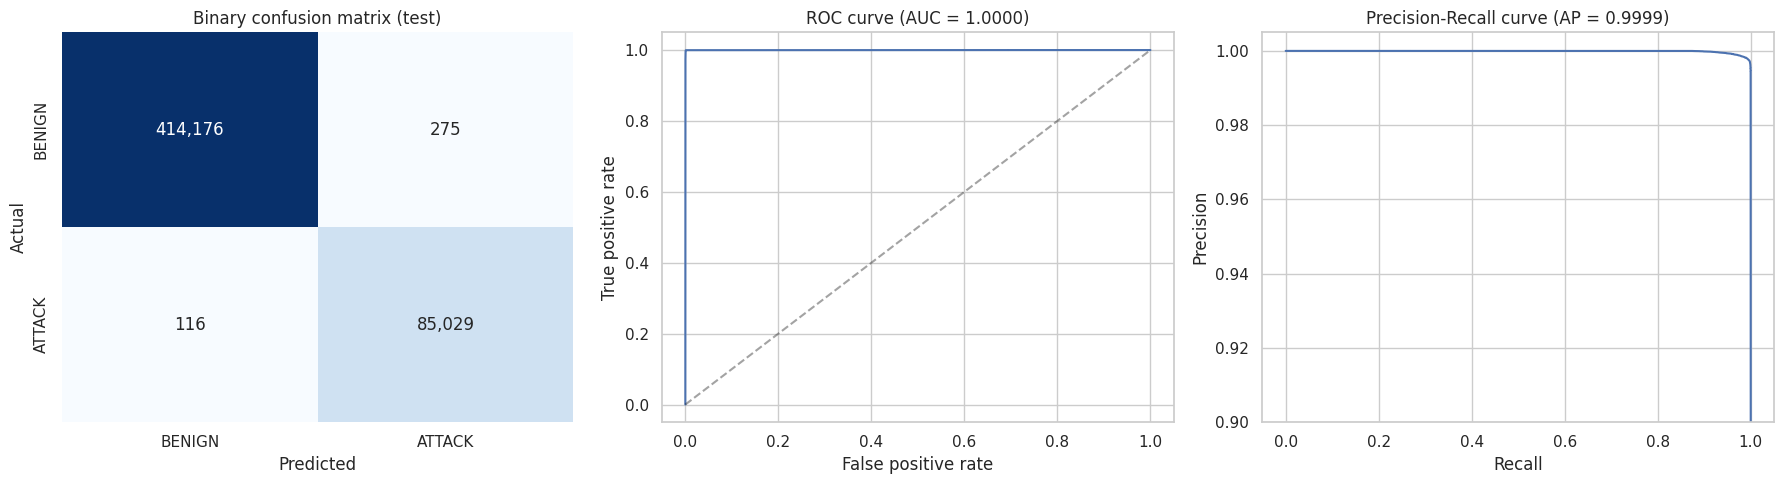

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/07_test_multiclass_confusion.png


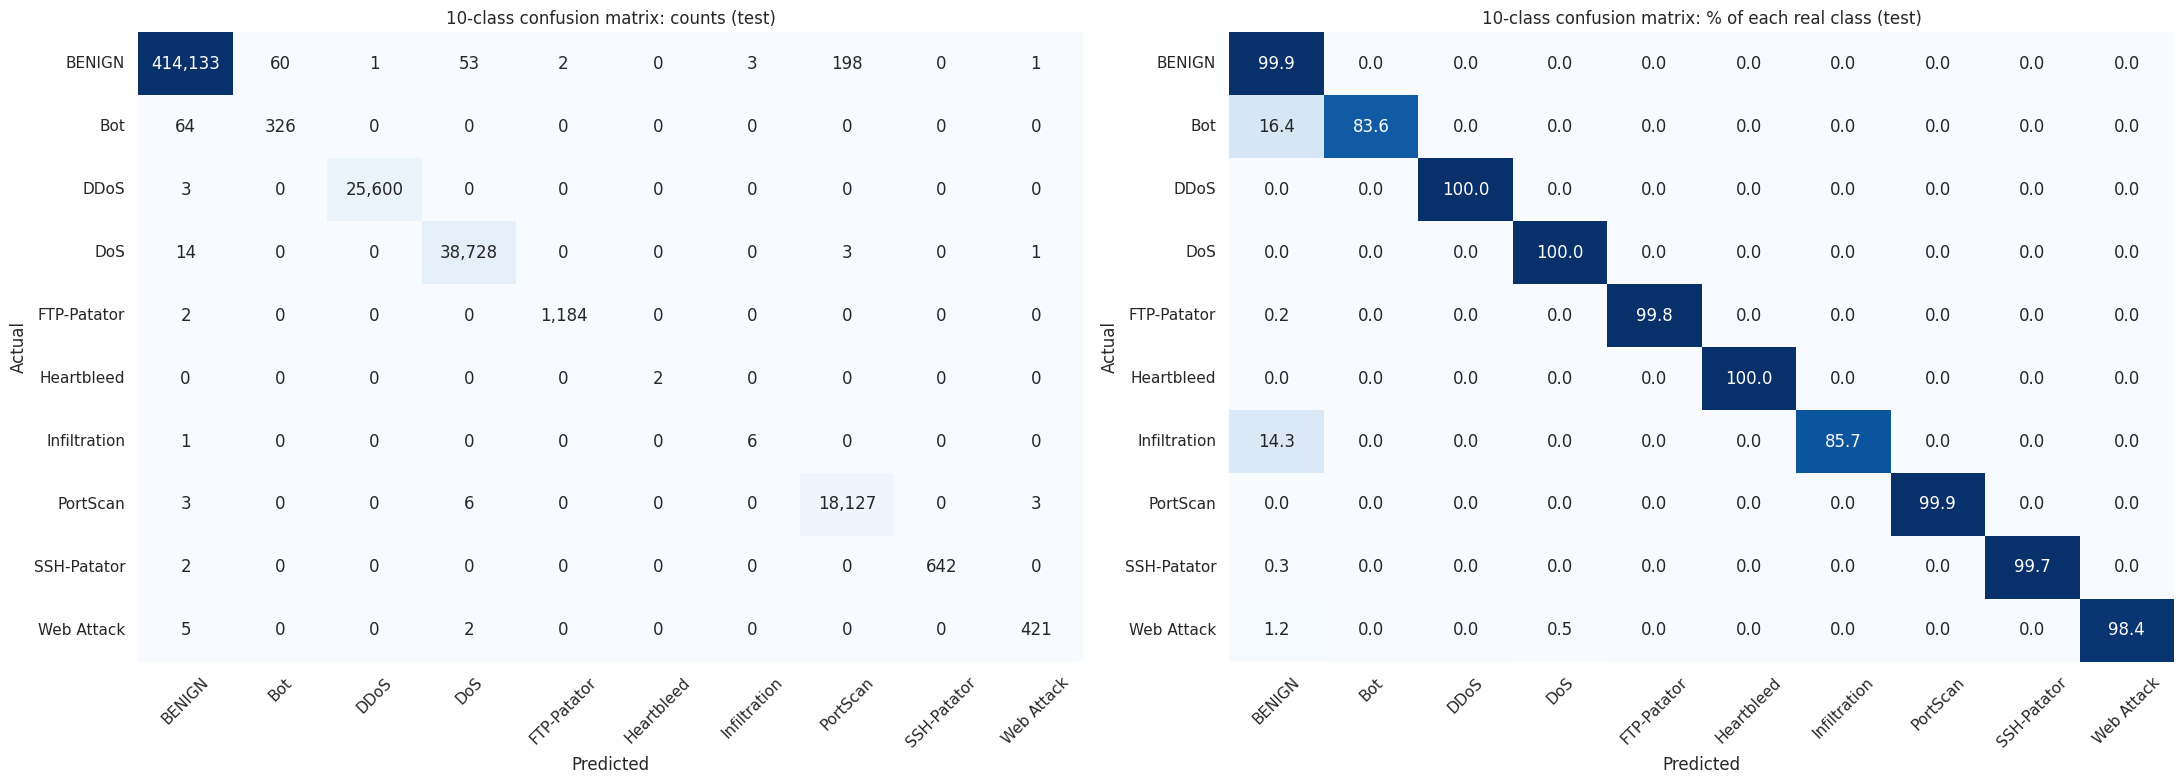

In [6]:
# Binary confusion matrix + ROC + PR
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y_test_bin, pred_b)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["BENIGN", "ATTACK"], yticklabels=["BENIGN", "ATTACK"])
axes[0].set_title("Binary confusion matrix (test)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test_bin, proba_b)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title(f"ROC curve (AUC = {bin_metrics['roc_auc']:.4f})")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")

pr, rc, _ = precision_recall_curve(y_test_bin, proba_b)
axes[2].plot(rc, pr)
axes[2].set_title(f"Precision-Recall curve (AP = {bin_metrics['pr_auc']:.4f})")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_ylim(0.9, 1.005)
save_fig("07_test_binary_curves")
plt.show()

# 10-class confusion matrix: counts and row-normalised (each row = 100% of that real class)
cm_m = confusion_matrix(y_test_multi, pred_m, labels=labels)
cm_pct = cm_m / cm_m.sum(axis=1, keepdims=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
sns.heatmap(cm_m, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title("10-class confusion matrix: counts (test)")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("10-class confusion matrix: % of each real class (test)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45)
save_fig("07_test_multiclass_confusion")
plt.show()

In [7]:
log_experiment(
    experiment_id="EXP-08_final_binary_test", task="Experiment A: binary",
    model="XGBoost (tuned)", features=f"CORR_FILTERED ({len(FEATURES)} features), signed-log transformed",
    preprocessing="original data (no resampling)", hyperparameters=json.dumps(BEST),
    split="trained on full train.parquet, scored once on locked test.parquet",
    metrics={k: round(float(v), 5) for k, v in bin_metrics.items() if k in
             ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "false_alarm_rate"]},
    notes="FINAL test result")
log_experiment(
    experiment_id="EXP-09_final_multiclass_test", task="Experiment B: multi-class (Label_Group)",
    model="XGBoost (tuned)", features=f"CORR_FILTERED ({len(FEATURES)} features), signed-log transformed",
    preprocessing="SMOTE (small classes to 2,000) on training data only", hyperparameters=json.dumps(BEST),
    split="trained on full train.parquet, scored once on locked test.parquet",
    metrics={k: round(float(v), 5) for k, v in multi_summary.items()},
    notes="FINAL test result; Heartbleed and Infiltration have only a handful of test rows")

for p_ in (sorted(MODEL_DIR.glob("*")) + sorted(TABLE_DIR.glob("07_*")) +
           sorted(FIG_DIR.glob("07_*")) + sorted(METRIC_DIR.glob("07_*"))):
    print(p_.name)

[logged experiment] EXP-08_final_binary_test
[logged experiment] EXP-09_final_multiclass_test
binary_model.pkl
label_mapping.json
model_features.json
multiclass_model.pkl
07_test_binary_metrics.csv
07_test_multiclass_per_class.csv
07_test_multiclass_summary.csv
07_test_binary_curves.png
07_test_multiclass_confusion.png
07_test_pred_binary.npy
07_test_pred_multiclass.npy
07_test_proba_binary.npy
